# ID2222 Homework 3: Counting triangles in graph streams

In this homework we implement reservoir sampling and use it in TRIÈST (De Stefani et al., KDD 2016) to estimate the number of triangles in a graph that arrives as a stream of edges. We implemented the two insertion-only variants from the paper. **TRIÈST-BASE** counts the triangles among the sampled edges and scales that count up. **TRIÈST-IMPR** counts on every arriving edge, also the ones that are not sampled, and in our experiments gives clearly better estimates. The code is plain Python (`triest.py`, `main.py`), and we test it on two SNAP graphs where the exact triangle count is known.

Contents: [1. Setup and data](#setup), [2. Reservoir sampling](#reservoir), [3. TRIÈST](#triest), [4. Tests](#checks), [5. Experiments](#experiment), [6. One stream in detail](#trace), [7. Conclusions](#conclusion)

Notation: $t$ is the number of edges seen so far, $M$ the reservoir capacity in edges, $T_t$ the exact number of triangles among the first $t$ edges, $\tau_t$ the number of triangles in the current sample and $\widehat T_t$ the estimate.

<a id="setup"></a>

## 1. Setup and data

We use two graphs from SNAP: [ca-GrQc](https://snap.stanford.edu/data/ca-GrQc.html), a collaboration network, and [p2p-Gnutella08](https://snap.stanford.edu/data/p2p-Gnutella08.html), a peer-to-peer network. Download [ca-GrQc.txt.gz](https://snap.stanford.edu/data/ca-GrQc.txt.gz) and [p2p-Gnutella08.txt.gz](https://snap.stanford.edu/data/p2p-Gnutella08.txt.gz) into `../datasets/TW3/` and leave them compressed. The datasets are not included in the ZIP. Install the notebook packages with `python -m pip install -r requirements.txt` and run the tests with `python -m unittest -v`.

Start Jupyter in `TW3` and run all cells. The same experiments can be run from the command line with `python main.py`, which takes these arguments:

| Argument | Default | Meaning |
| --- | --- | --- |
| `--data` | `../datasets/TW3/ca-GrQc.txt.gz` and `../datasets/TW3/p2p-Gnutella08.txt.gz` | One or more two-column edge files |
| `--capacities` | `500 2000 5000` | Reservoir sizes M, at least 6. A run with M equal to the number of edges is always added |
| `--seeds` | `0 1 2 3 4 5 6 7 8 9` | Sampling seeds, one run each |
| `--order-seed` | `42` | Seed for shuffling the edge order, shared by both variants |
| `--output-dir` | `results/` | Output directory. The notebook writes to `results/notebook/` instead |

In [1]:
import csv
import io
import itertools
import random
import sys
import time
import unittest
from html import escape
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import HTML, display

# Locate the experiment source when starting from TW3 or the project root.
HERE = Path.cwd()
if not (HERE / "triest.py").is_file():
    HERE = HERE / "Coding" / "TW3"
if not (HERE / "triest.py").is_file():
    raise FileNotFoundError("Start the notebook from TW3 or the ID2222 root.")
sys.path.insert(0, str(HERE))

from main import DEFAULT_ORDER_SEED, DEFAULT_PATHS, run_experiments
from triest import Reservoir, Triest, exact_triangles, read_graph

for path in DEFAULT_PATHS:
    if not path.is_file():
        raise FileNotFoundError(f"Download the data to {path} first.")

OUT = HERE / "results" / "notebook"
print(f"Python {sys.version.split()[0]} · Output in {OUT.relative_to(HERE)}")


def show_table(headers, rows):
    """Display selected experiment fields as a table."""
    header = "".join(f'<th scope="col">{escape(name)}</th>' for name in headers)
    body = "".join(
        "<tr>" + "".join(f"<td>{escape(str(value))}</td>" for value in row) + "</tr>"
        for row in rows
    )
    display(HTML(f"<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>"))

Python 3.12.16 · Output in results\notebook


<a id="reservoir"></a>

## 2. Reservoir sampling

`Reservoir.update` is the standard reservoir sampling algorithm (Algorithm R). The first $M$ items go straight into the reservoir. For item $t > M$ we draw $j$ uniformly from $\{0, \dots, t-1\}$. If $j < M$ the new item overwrites slot $j$, otherwise it is dropped. The new item is therefore kept with probability $M/t$, and an item that is already in the sample survives this step with probability $1 - 1/t$, so it is still in the sample with probability

$$
\frac{M}{t-1}\left(1-\frac{1}{t}\right)=\frac{M}{t}.
$$

TRIÈST needs slightly more than that: every set of $M$ items has to be equally likely to be the sample, because the estimator depends on three edges being in the sample at the same time. This follows by induction on $t$. A sample without item $t$ can only come from the same sample followed by a skip, with probability $(t-M)/t$. A sample containing item $t$ can come from $t-M$ different previous samples, each followed by overwriting the right slot with probability $1/t$. Both give the same probability, so uniformity carries over from step $t-1$ to step $t$.

A small trace with $M=6$ and seed 7:

In [2]:
sampler = Reservoir(capacity=6, seed=7)
sampling_steps = []

for item in range(1, 13):
    # Save the slot contents immediately so each row shows its own state.
    accepted, removed = sampler.update(item)
    if removed is not None:
        action = f"Replace {removed}"
    else:
        action = "Append" if accepted else "Skip"
    sampling_steps.append((item, action, ", ".join(map(str, sampler.items))))

show_table(("Incoming item", "Action", "Current sample"), sampling_steps)
assert len(sampler.items) == 6

Incoming item,Action,Current sample
1,Append,1
2,Append,"1, 2"
3,Append,"1, 2, 3"
4,Append,"1, 2, 3, 4"
5,Append,"1, 2, 3, 4, 5"
6,Append,"1, 2, 3, 4, 5, 6"
7,Replace 3,"1, 2, 7, 4, 5, 6"
8,Replace 7,"1, 2, 8, 4, 5, 6"
9,Skip,"1, 2, 8, 4, 5, 6"
10,Replace 1,"10, 2, 8, 4, 5, 6"


Item 7 replaces item 3, item 8 replaces item 7 and item 9 is dropped. A single run like this cannot show that the sample is uniform, so we check the inclusion frequencies over many runs in Section 4.

<a id="triest"></a>

## 3. TRIÈST

### BASE

BASE keeps the $M$ sampled edges as adjacency sets and maintains $\tau_t$, the number of triangles formed by sampled edges. When an edge $(u,v)$ enters the sample, every common neighbour $w$ of $u$ and $v$ in the sample closes a new triangle, so `Triest._count` just intersects the two neighbour sets. If the new edge evicts an old one, we first subtract the triangles the old edge was part of and remove it, and only then count the triangles closed by the new edge. Per-vertex (local) counts are updated in the same way when they are enabled.

For $t > M$ a triangle is in the sample only if all three of its edges are, which happens with probability

$$
p_3 = \frac{M}{t}\frac{M-1}{t-1}\frac{M-2}{t-2},
$$

so `Triest.estimate` returns $\widehat T_t=\tau_t/p_3$, and simply $\tau_t$ while $t \le M$. This is why the estimates are usually not integers. With $t=8$ and $M=6$, for example, $p_3=5/14$, and two sampled triangles give an estimate of 5.6.

As a first check we stream the six edges of the complete graph on four vertices into BASE with $M=6$. Everything fits in the reservoir, so we expect exactly 4 triangles and 3 per vertex.

In [3]:
# The six pairs among four vertices fill the reservoir exactly.
clique_edges = list(itertools.combinations(range(4), 2))
base = Triest(6, local=True)
clique_steps = []

for u, v in clique_edges:
    estimate = base.update(u, v)
    clique_steps.append((f"{u}–{v}", base.counter, f"{estimate:g}"))

show_table(("Incoming edge", "Sample triangles", "Global estimate"), clique_steps)
assert base.estimate() == 4
assert all(base.estimate(node) == 3 for node in range(4))
print("Each of the four vertices belongs to three triangles.")

Incoming edge,Sample triangles,Global estimate
0–1,0,0
0–2,0,0
0–3,0,0
1–2,1,1
1–3,2,2
2–3,4,4


Each of the four vertices belongs to three triangles.


Edge $(1,2)$ closes the first triangle through vertex 0, and the last edge $(2,3)$ has two common neighbours, so it adds two triangles at once.

### IMPR

IMPR changes two things. It counts the triangles that an arriving edge closes in the sample *before* the sampling decision, so edges that are never stored still contribute. And it never decrements the counter when an edge is evicted. Each triangle found at time $t$ is weighted by

$$
\eta_t=\max\left(1,\frac{(t-1)(t-2)}{M(M-1)}\right),
$$

which is one over the probability that the other two edges are both in the sample at that moment. For $t=8$ and $M=6$ this gives $7/5 = 1.4$. The counter itself is the estimate, no scaling at the end.

Both variants store at most $M$ edges for the global estimate. With local counts enabled, IMPR can end up with a counter for every vertex it has seen. Our implementation assumes an insertion-only stream of undirected edges without duplicates or self-loops. A duplicate can only be detected while the first copy is still in the sample, so we clean the input before streaming it (Section 5).

<a id="checks"></a>

## 4. Tests

[test_triest.py](test_triest.py) contains six unit tests:

- **Reservoir uniformity.** Over 4,000 runs that sample 6 of 20 items, every item should be kept about 1,200 times.
- **Exact case.** $K_6$ fits completely in the sample, so both variants must return 20 triangles and 10 per vertex.
- **BASE bookkeeping.** We stream $K_{12}$ with $M=10$ and, after every single update, compare the BASE counters with an exact recount of the current sample. This is the test that would show mistakes in the eviction logic.
- **Unbiasedness.** Over 3,000 seeds on $K_5$ with $M=6$, the mean estimate of both variants should be within 0.25 of the true 10.
- **Trivial streams.** A path gives 0, and the same seed gives the same sample.
- **Input handling.** The loader removes reversed duplicates and self-loops, and invalid input raises an error.

In [4]:
suite = unittest.defaultTestLoader.discover(str(HERE), pattern="test_triest.py")
# Show the test count on success and preserve the diagnostics on failure.
test_log = io.StringIO()
test_result = unittest.TextTestRunner(stream=test_log).run(suite)
assert test_result.wasSuccessful(), test_log.getvalue()
print(f"Passed {test_result.testsRun} independent tests.")

Passed 6 independent tests.


<a id="experiment"></a>

## 5. Experiments on the SNAP graphs

### 5.1 Data and exact counts

`read_graph` treats every record as an undirected edge and drops self-loops and duplicates. `exact_triangles` then counts the triangles of the cleaned graph offline, which is our ground truth.

We run both variants with $M = 500$, $2{,}000$ and $5{,}000$ and ten sampling seeds each, plus one run per seed with $M$ equal to the number of edges, where the estimate must be exact. The edge order is shuffled once with seed 42, so BASE and IMPR see the same stream. In total this is 160 runs.

In [5]:
started = time.perf_counter()
runs, summary, datasets = run_experiments(output_dir=OUT)
# Total runtime includes loading and writing. Stage timings below use separate clocks.
elapsed = time.perf_counter() - started

names = {
    "ca-GrQc.txt.gz": "GrQc",
    "p2p-Gnutella08.txt.gz": "Gnutella",
}
published_counts = {"GrQc": 48_260, "Gnutella": 2_383}
data_rows = []

for dataset in datasets:
    name = names[dataset["dataset"]]
    exact = dataset["exact_triangles"]
    # A disagreement with SNAP can reveal a different input or cleaning rule.
    assert exact == published_counts[name]
    data_rows.append((
        name, f'{dataset["nodes"]:,}', f'{dataset["raw_edges"]:,}',
        dataset["self_loops"], f'{dataset["duplicate_edges"]:,}', f'{dataset["edges"]:,}',
        f"{exact:,}", f'{1000 * dataset["preprocess_seconds"]:.1f}',
        f'{1000 * dataset["exact_seconds"]:.1f}',
    ))

show_table(
    ("Dataset", "Vertices", "Raw edges", "Self-loops", "Duplicates", "Clean edges",
     "Exact triangles", "Load and clean (ms)", "Exact count (ms)"),
    data_rows,
)
print(f"Completed {len(runs)} runs in {elapsed:.2f} s, including loading, baseline, and file writes.")
assert len(runs) == 160

Dataset,Vertices,Raw edges,Self-loops,Duplicates,Clean edges,Exact triangles,Load and clean (ms),Exact count (ms)
GrQc,"5,242","28,980",12,"14,484","14,484","48,260",43.4,81.8
Gnutella,"6,301","20,777",0,0,"20,777","2,383",51.5,23.7


Completed 160 runs in 6.64 s, including loading, baseline, and file writes.


Our exact counts, 48,260 and 2,383, are the same as the triangle counts listed on the SNAP pages. GrQc has 28,980 records, but every edge appears in both directions and there are 12 self-loops, so 14,484 edges remain. SNAP reports 14,496 edges because it includes the self-loops. Gnutella has no duplicates. Loading and the exact count each take less than 0.1 s per graph, and the whole experiment with all 160 runs took 6.64 s.

### 5.2 Accuracy and running time

For each setting the table shows the mean and standard deviation of the ten estimates, the mean absolute relative error $|\widehat T-T|/T$, and the mean time for one pass over the stream. The time covers only the update loop, not loading or the exact count. The single runs are in `runs.csv`. Before printing we also check that all 40 full-capacity runs return exactly the right count.

In [6]:
# Full capacity removes sampling error. Check each trial before averaging.
full_runs = [run for run in runs if run["capacity"] >= run["edges"]]
assert len(full_runs) == 40
assert all(run["estimate"] == run["exact"] for run in full_runs)

result_headers = (
    "Capacity M", "Variant", "Mean estimate", "Estimate SD", "Mean absolute relative error", "Mean stream time (ms)",
)
for filename, name in names.items():
    display(HTML(f"<h4>{name} · Exact count {published_counts[name]:,}</h4>"))
    # Place BASE and IMPR next to each other at the same capacity.
    group = sorted(
        (row for row in summary if row["dataset"] == filename),
        key=lambda row: (row["capacity"], row["variant"]),
    )
    show_table(result_headers, [
        (
            f'{row["capacity"]:,}', row["variant"].upper(),
            f'{row["mean_estimate"]:,.1f}', f'{row["std_estimate"]:,.1f}',
            f'{row["mean_relative_error"]:.2%}', f'{1000 * row["mean_seconds"]:.1f}',
        )
        for row in group
    ])

Capacity M,Variant,Mean estimate,Estimate SD,Mean absolute relative error,Mean stream time (ms)
500,BASE,"44,009.7","32,189.7",50.93%,22.1
500,IMPR,"51,261.2","5,362.4",10.60%,24.2
"2,000",BASE,"49,630.4","4,417.9",8.12%,23.3
"2,000",IMPR,"47,946.9","1,833.5",2.72%,26.8
"5,000",BASE,"47,697.1","2,417.1",3.97%,28.4
"5,000",IMPR,"48,153.6","1,629.1",2.63%,38.5
"14,484",BASE,"48,260.0",0.0,0.00%,38.4
"14,484",IMPR,"48,260.0",0.0,0.00%,49.0


Capacity M,Variant,Mean estimate,Estimate SD,Mean absolute relative error,Mean stream time (ms)
500,BASE,0.0,0.0,100.00%,39.1
500,IMPR,"1,913.4","2,130.3",69.18%,34.9
"2,000",BASE,"2,806.6","1,323.1",43.56%,42.4
"2,000",IMPR,"2,478.5",418.7,14.20%,45.4
"5,000",BASE,"2,333.0",601.8,19.58%,51.7
"5,000",IMPR,"2,368.6",238.8,8.99%,59.2
"20,777",BASE,"2,383.0",0.0,0.00%,50.4
"20,777",IMPR,"2,383.0",0.0,0.00%,58.9


IMPR has a lower error than BASE in every setting where the sample is smaller than the graph. On GrQc the error of BASE drops from 50.93% at $M=500$ to 3.97% at $M=5{,}000$, while IMPR is already at 10.60% with 500 edges. Gnutella is harder because it has far fewer triangles relative to its size. With $M=500$ none of the ten BASE samples contained a complete triangle, so every estimate was 0. IMPR still gets some signal there because it looks at every incoming edge.

The mean absolute error is larger than the error of the mean estimate, since over- and underestimates cancel in the mean. For BASE on GrQc with $M=5{,}000$, the average of the ten estimates (47,697.1) is only about 1.2% below the true count.

One pass over a stream of 14,484 or 20,777 edges takes between 22 and 59 ms. IMPR is usually a little slower because it intersects neighbour sets for every edge, not just for the sampled ones.

### 5.3 Error and time as a function of M

The same numbers plotted against $M$ on a log scale, GrQc on the left and Gnutella on the right. The last point in each column is the full-capacity run.

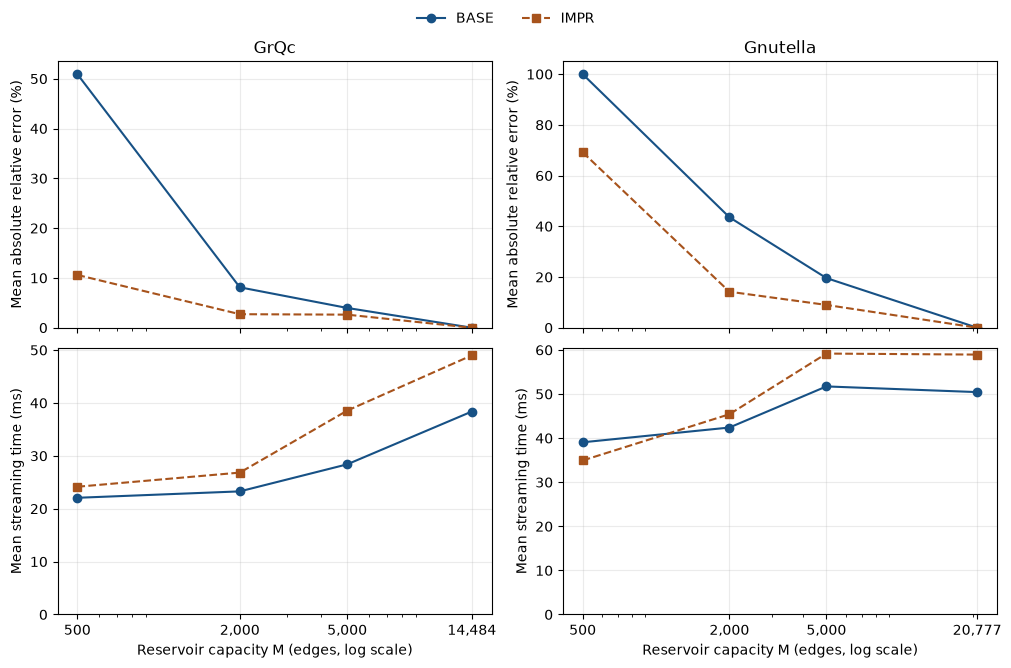

In [7]:
styles = {
    "base": {"marker": "o", "linestyle": "-", "color": "#175185", "label": "BASE"},
    "impr": {"marker": "s", "linestyle": "--", "color": "#a7531c", "label": "IMPR"},
}
# Share capacity ticks between the error and runtime panels for each graph.
fig, axes = plt.subplots(2, 2, figsize=(10, 6.6), sharex="col", layout="constrained")

for col, (filename, name) in enumerate(names.items()):
    accuracy_ax, runtime_ax = axes[:, col]
    for variant, style in styles.items():
        group = [
            row for row in summary
            if row["dataset"] == filename and row["variant"] == variant
        ]
        capacities = [row["capacity"] for row in group]
        accuracy_ax.plot(
            capacities, [100 * row["mean_relative_error"] for row in group], **style,
        )
        runtime_ax.plot(
            capacities, [1000 * row["mean_seconds"] for row in group], **style,
        )

    accuracy_ax.set_title(name)
    accuracy_ax.set_ylabel("Mean absolute relative error (%)")
    runtime_ax.set_ylabel("Mean streaming time (ms)")
    runtime_ax.set_xlabel("Reservoir capacity M (edges, log scale)")
    # The log axis separates small capacities and still shows the actual full capacity.
    runtime_ax.set_xscale("log")
    runtime_ax.set_xticks(capacities, [f"{capacity:,}" for capacity in capacities])

for ax in axes.flat:
    ax.grid(alpha=0.25)
    ax.set_ylim(bottom=0)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncols=2, frameon=False)
fig.savefig(OUT / "accuracy_runtime.png", dpi=140)
plt.show()

<a id="trace"></a>

## 6. One stream in detail

To see how the estimates develop during a stream, we follow GrQc with $M=2{,}000$ and seed 0, using the same edge order as above. Every 1,000 edges we compare the estimates with the exact count of the edges seen so far. These exact recounts are only for the plot and are not part of the timings in Section 5.

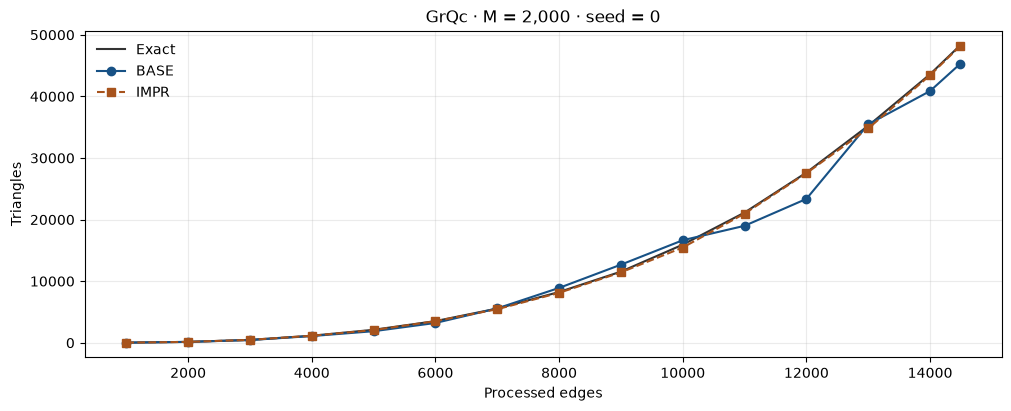

In [8]:
edges, _ = read_graph(DEFAULT_PATHS[0])
# Reuse the main experiment's edge order to match its final result for seed 0.
random.Random(DEFAULT_ORDER_SEED).shuffle(edges)
estimators = {variant: Triest(2000, seed=0, variant=variant) for variant in styles}
trace = []

for processed, edge in enumerate(edges, 1):
    for estimator in estimators.values():
        estimator.update(*edge)

    # Count the prefix offline every 1,000 edges to keep the exact checks practical.
    if processed % 1000 == 0 or processed == len(edges):
        exact, _ = exact_triangles(edges[:processed])
        trace.append({
            "t": processed,
            "exact": exact,
            **{variant: estimator.estimate() for variant, estimator in estimators.items()},
        })

# Save the plotted data so each curve can be checked by processed edge count.
with (OUT / "stream_trace.csv").open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(trace[0]))
    writer.writeheader()
    writer.writerows(trace)

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
processed_edges = [row["t"] for row in trace]
ax.plot(processed_edges, [row["exact"] for row in trace], color="#333333", label="Exact")
for variant, style in styles.items():
    ax.plot(processed_edges, [row[variant] for row in trace], **style)

ax.set(title="GrQc · M = 2,000 · seed = 0", xlabel="Processed edges", ylabel="Triangles")
ax.grid(alpha=0.25)
ax.legend(loc="upper left", frameon=False)
fig.savefig(OUT / "stream_trace.png", dpi=140)
plt.show()

Up to 2,000 edges everything fits in the reservoir and both estimates are exact (20 and 142 triangles). After that they drift. At 3,000 edges the exact count is 467, BASE gives 442.3 and IMPR 470.8. BASE overshoots around 9,000 edges and finishes at 45,256.8, while IMPR finishes at 48,150.4, against 48,260 exactly. In this run IMPR stays much closer to the exact curve the whole time.

<a id="conclusion"></a>

## 7. Conclusions

Reservoir sampling together with TRIÈST gives usable triangle estimates from a fixed number of edges. When the whole graph fits in the reservoir, all 40 runs returned the exact count. With smaller samples IMPR had a lower error than BASE in every setting we tried, at a small extra cost in time. How large the sample has to be depends a lot on the graph. With 5,000 edges BASE was within 4% on GrQc but still about 20% off on Gnutella, which has far fewer triangles. All results are for one fixed edge order and ten seeds per setting.

The estimators themselves only need $O(M)$ memory. The cleaning, shuffling and exact counting in our experiments load the whole graph, but they are only there so that we can measure the error.

**References.** BASE and IMPR follow Sections 4.1 and 4.2 of [De Stefani et al., TRIÈST, KDD 2016](https://www.kdd.org/kdd2016/papers/files/rfp0465-de-stefaniA.pdf). Assignment: [Canvas Homework 3](https://canvas.kth.se/courses/65339/assignments/402870).

### AI disclosure

We used generative AI to help us understand the assignment, review the structure of the algorithm, and improve the documentation and presentation. We wrote and are responsible for the final code, chose the parameters, and ran all experiments and tests ourselves on the dataset above. [course policy on generative AI](https://canvas.kth.se/courses/65339/pages/use-of-generative-ai).